# Junta: asistencia marginal no garantiza disponibilidad de quórum

## Resumen
En el caso sintético, independencia de marginales predice0,8512sin reservas yparece cumplir meta0,85; mezcla exacta conausencia común da0,76. Dos participantes dereserva autorizados elevan disponibilidad a0,9139concoste2. No se mide calidad de votos ni aprobación.

## Modelo ycondiciones
Comitébase4, quórumfijo3 ypresencia obligatoria del miembro0(risk_lead). Régimen normalpeso0,8: asistencia(0,95;1;1;1). Disrupción compartidapeso0,2: (0,95;0;0;0). Dentro de cada régimen se asume independencia; incondicionalmente los3miembros comparten ausencia. Reservas autorizadas tienenprobabilidad0,9ysonindependientesdelrégimen por supuesto.

Se enumeran máscarasX∈{0,1}^N ycalculaΣr w_rΣX I(sumX≥3,X0=1)Πi p_ri^Xi(1−p_ri)^(1−Xi). El baseline reemplaza la mezcla porproducto de marginales. Objetivo: menorcoste de reservas que alcanza meta, manteniendo quórum3yrolobligatorio. No se autorizan sustituciones reales por elmodelo.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image
cfg=json.loads(Path('config.json').read_text())
summary=json.loads(Path('results/summary.json').read_text())
display(cfg)

{'regimes': [{'name': 'normal', 'weight': 0.8, 'attendance': [0.95, 1, 1, 1]},
  {'name': 'shared_disruption', 'weight': 0.2, 'attendance': [0.95, 0, 0, 0]}],
 'members': ['risk_lead', 'member_A', 'member_B', 'member_C'],
 'quorum': 3,
 'mandatory': [0],
 'standby_menu': [0, 1, 2],
 'standby_attendance': 0.9,
 'unit_standby_cost': 1,
 'target': 0.85,
 'units': 'synthetic availability probability per scheduled session; unit cost arbitrary; authorized extra participants count toward fixed quorum by assumption',
 'hypothesis': 'marginal independence can falsely pass target0.85; exact regime-aware plan reaches target with minimum authorized standbys'}

## Planes ybaseline
Mismas probabilidades marginales, diferente distribución conjunta. Las224filas de máscaras para0/1/2reservas se guardan sin selección, incluidas masas0para conservar elespacio completo.

,standbys,cost,exact_availability,independent_marginal,states
0,0,0,0.7600,0.85120,32
1,1,1,0.7600,0.93328,64
2,2,2,0.9139,0.94764,128


{'selected_exact': {'standbys': 2, 'cost': 2, 'availability': 0.9139},
 'baseline_independent': {'standbys': 0,
  'cost': 0,
  'availability': 0.8512000000000001},
 'actual_baseline_availability': 0.76,
 'independence_error': 0.09120000000000006,
 'seconds': 0.0032705899999427857,
 'python_peak_bytes': 32863,
 'python': '3.12.14',
 'platform': 'Linux-6.18.55-x86_64-with-glibc2.39'}

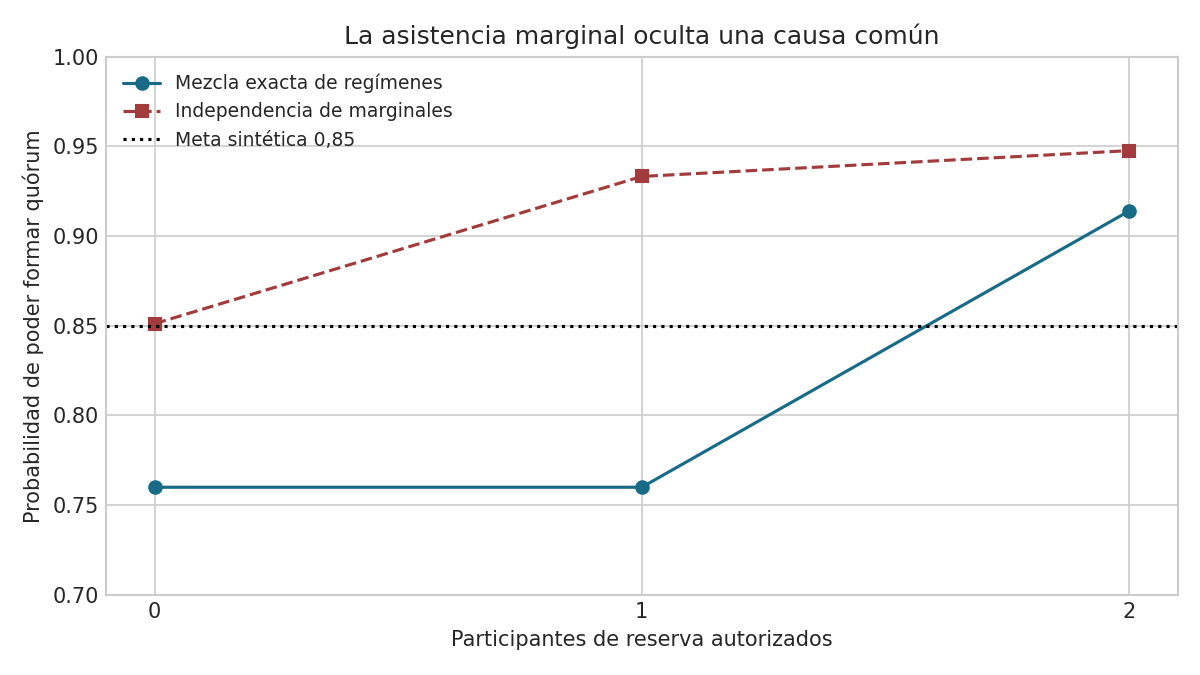

In [2]:
display(pd.read_csv('results/plans.csv').round(5))
display(summary)
display(Image(filename='results/quorum.png'))

## Falsación ylímites
La independencia no falla siempre hacia elmismo lado. Aquí da un falso pase. Elrolobligatorio conprobabilidad0,95limita toda disponibilidad a≤0,95; meta0,97es imposible. Si sube disrupción a0,8, dosreservas tampoco cumplen. Si quórum se eleva a4, no basta este menú. No se baja quórum para forzar factibilidad.

In [3]:
display(pd.read_csv('results/sensitivity.csv'))
display(pd.read_csv('results/scaling.csv'))
assert summary['baseline_independent']['availability']>=cfg['target']>summary['actual_baseline_availability']
assert summary['selected_exact']['availability']>=cfg['target']

,disruption_weight,feasible,standbys,cost,availability
0,0.1,True,0.0,0.0,0.8550
1,0.2,True,2.0,2.0,0.9139
2,0.4,True,2.0,2.0,0.8778
3,0.8,False,NaN,NaN,NaN


,members,states,median_seconds,repetitions
0,4,32,0.000046,5
1,6,128,0.000204,5
2,8,512,0.000950,5


## Decisión
Continuar solo como prueba de resiliencia con2reservas elegibles si reglas vigentes ysupuestos lo permiten. Ajustar calendario/modos remotos si haycorrelación de ausencias. Detener propuesta cuando menú no alcanza meta. No asesoría legal, cambio de estatutos, evidencia de calidad decisional ni probabilidad de aprobación. ComponenteS2 sintético, programa21S1sinrecertificar.